# 📰 Detección de Fake News con PLN
## TF-IDF (Baseline) vs ELMo (Embeddings Contextuales)

**Curso:** Procesamiento de Lenguaje Natural Aplicado a Finanzas  
**Dataset:** Kaggle — *Fake and Real News* (True.csv / Fake.csv)  

### Pipeline del notebook
| Sección | Descripción |
|---------|-------------|
| 1 | Instalación y librerías |
| 2 | Carga y exploración del dataset |
| 3 | Análisis estilométrico descriptivo |
| 4 | Preprocesamiento inteligente v3 |
| 5 | Visualización de N-gramas distintivos |
| 6 | Baseline: TF-IDF |
| 7 | Modelo avanzado: ELMo |



## Sección 1 · Instalación y carga de librerías

In [ ]:
# Instalación de dependencias en caso de no estar disponibles
!pip install -q tensorflow tensorflow-hub

import os, re, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, accuracy_score
)

# Descargas NLTK
for pkg in ['stopwords', 'wordnet', 'omw-1.4', 'punkt', 'punkt_tab']:
    nltk.download(pkg, quiet=True)

# Estilo global
sns.set(style='whitegrid')
plt.rcParams['figure.dpi'] = 100

# Semillas de reproducibilidad
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
print('✅ Librerías cargadas correctamente.')


✅ Librerías cargadas correctamente.


## Sección 2 · Carga y exploración inicial del dataset

El dataset proviene de Kaggle ([*Fake and Real News*](https://www.kaggle.com/datasets/clmentbisaillon/fake-and-real-news-dataset)):
- `True.csv`: noticias reales de la agencia **Reuters**.
- `Fake.csv`: noticias falsas etiquetadas por **PolitiFact**.

Asignamos `target = 1` (Real) y `target = 0` (Fake), concatenamos y barajamos con semilla fija.


In [ ]:
import csv

df_true = pd.read_csv('/content/True.csv')
df_fake = pd.read_csv('/content/Fake.csv')

df_true['target'] = 1
df_fake['target'] = 0

df = (pd.concat([df_true, df_fake])
        .sample(frac=1, random_state=SEED)
        .reset_index(drop=True))

# Consolidar title + text en una sola columna de análisis
df['text'] = (
    df['title'].fillna('').astype(str)
    + ' '
    + df['text'].fillna('').astype(str)
).str.strip()

# Mantener solo las columnas necesarias
df = df[['text', 'target']].copy()

print(f'Total de noticias : {len(df):,}')
print(f'  · Reales (1)   : {(df.target==1).sum():,}')
print(f'  · Fake   (0)   : {(df.target==0).sum():,}')
print(f'Columnas          : {list(df.columns)}')
df.head(5)


Total de noticias : 44,898
  · Reales (1)   : 21,417
  · Fake   (0)   : 23,481
Columnas          : ['text', 'target']


,text,target
0,BREAKING: GOP Chairman Grassley Has Had Enough...,0
1,Failed GOP Candidates Remembered In Hilarious ...,0
2,Mike Pence’s New DC Neighbors Are HILARIOUSLY ...,0
3,California AG pledges to defend birth control ...,1
4,AZ RANCHERS Living On US-Mexico Border Destroy...,0


/tmp/ipykernel_5042/1950972973.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='target', palette=['salmon', 'steelblue'], ax=axes[1])
/tmp/ipykernel_5042/1950972973.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Fake (0)', 'Real (1)'])


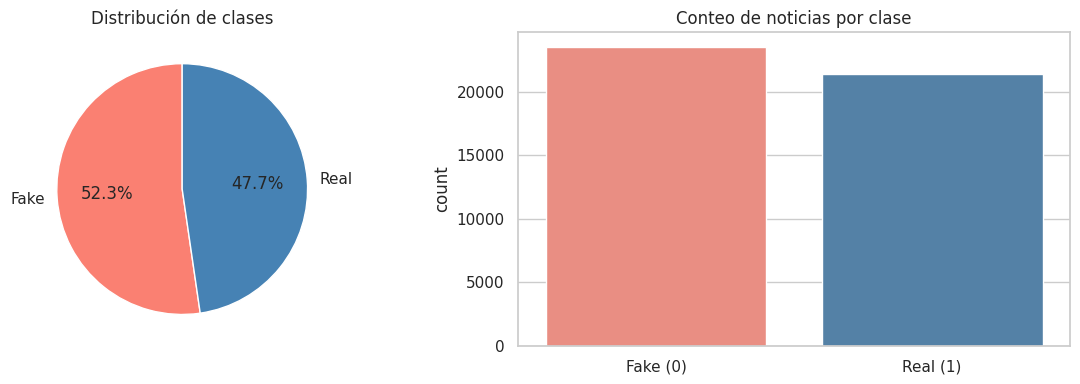

In [ ]:
# Distribución de clases
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Pie chart
counts = df['target'].value_counts()
axes[0].pie(counts, labels=['Fake', 'Real'], autopct='%1.1f%%',
             colors=['salmon', 'steelblue'], startangle=90)
axes[0].set_title('Distribución de clases')

# Bar chart
sns.countplot(data=df, x='target', palette=['salmon', 'steelblue'], ax=axes[1])
axes[1].set_xticklabels(['Fake (0)', 'Real (1)'])
axes[1].set_title('Conteo de noticias por clase')
axes[1].set_xlabel('')
plt.tight_layout()
plt.show()


## Sección 3 · Análisis estilométrico descriptivo

Antes de modelar, extraemos **características de estilo de escritura** independientes del contenido semántico:

| Feature | Definición |
|---------|------------|
| `word_count` | Número total de palabras |
| `caps_ratio` | Proporción de letras mayúsculas sobre el total de caracteres |
| `exclamation_count` | Conteo absoluto de signos `!` |
| `lexical_richness` | Type-Token Ratio: Riqueza léxica|


In [ ]:
def extraer_metadata(texto):
    texto = str(texto)
    words = texto.split()
    return pd.Series({
        'word_count'        : len(words),
        'caps_ratio'        : sum(1 for c in texto if c.isupper()) / len(texto) if len(texto) > 0 else 0,
        'exclamation_count' : texto.count('!'),
        'lexical_richness'  : len(set(words)) / len(words) if len(words) > 0 else 0
    })

print('Extrayendo metadatos estilísticos...')
df_meta = df['text'].apply(extraer_metadata)
df = pd.concat([df, df_meta], axis=1)

print('\nMedia de features por clase:')
display(df.groupby('target')[['caps_ratio','lexical_richness','exclamation_count','word_count']]
          .mean()
          .rename(index={0:'Fake (0)', 1:'Real (1)'})
          .round(4))


Extrayendo metadatos estilísticos...

Media de features por clase:


,caps_ratio,lexical_richness,exclamation_count,word_count
target,,,,
Fake (0),0.0724,0.6471,0.8765,437.9307
Real (1),0.0421,0.6275,0.0628,395.5946


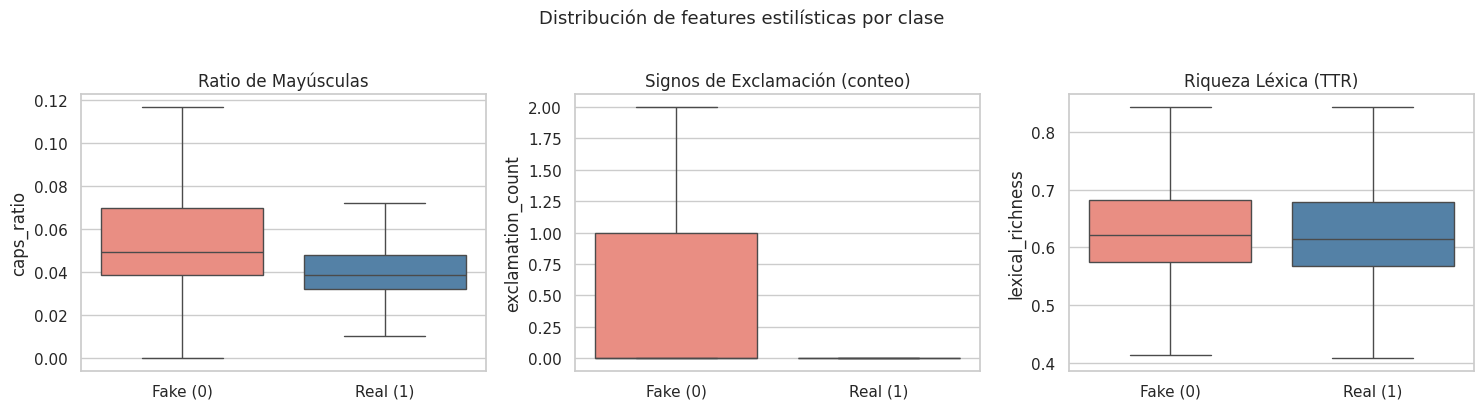

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
features = ['caps_ratio', 'exclamation_count', 'lexical_richness']
titles   = ['Ratio de Mayúsculas', 'Signos de Exclamación (conteo)', 'Riqueza Léxica (TTR)']

# Creamos una columna auxiliar de string solo para el gráfico
df['target_label'] = df['target'].map({0: 'Fake (0)', 1: 'Real (1)'})

for ax, feat, title in zip(axes, features, titles):
    sns.boxplot(
        data=df,
        x='target_label',
        y=feat,
        hue='target_label',
        palette={'Fake (0)': 'salmon', 'Real (1)': 'steelblue'},
        order=['Fake (0)', 'Real (1)'],
        legend=False,
        showfliers=False,
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel('')

plt.suptitle('Distribución de features estilísticas por clase', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

# Eliminamos la columna auxiliar para no contaminar el dataframe
df.drop(columns=['target_label'], inplace=True)



## Sección 4 · Preprocesamiento inteligente v3

El pipeline de limpieza aplica los siguientes pasos en orden:

1. **Normalización** a minúsculas.
2. **Eliminación de firmas de agencia** (`(reuters)`, `- reuters`) — evita *data leakage* por fuente.
3. **Limpieza de caracteres no alfabéticos** con regex `[^a-z\s]`.
4. **Tokenización profesional** con `word_tokenize` de NLTK.
5. **Stopwords selectivas**: se preservan negaciones (`not`, `no`, `never`, etc.) que son clave para el significado.
6. **Ruido específico**: se eliminan nombres de políticos, redes sociales y términos técnicos irrelevantes.
7. **Lematización** con `WordNetLemmatizer` (sin alterar las negaciones).


In [ ]:
def preprocesamiento_inteligente_v3(texto):
    texto = str(texto).lower()
    texto = re.sub(r'^\s*reuters\s*|- reuters\s*|\(reuters\)', '', texto)
    texto = re.sub(r'[^a-z\s]', ' ', texto)
    tokens = word_tokenize(texto)

    stop_words = set(stopwords.words('english'))
    negaciones = {'not', 'no', 'never', 'neither', 'nor', 'none'}
    stop_words -= negaciones

    ruido = {
        'said', 'would', 'also', 'told', 'reuters', 'washington',
        'pic', 'twitter', 'image', 'video', 'watch', 'http', 'https'
    }
    stop_words |= ruido

    lemmatizer = WordNetLemmatizer()
    tokens_limpios = [
        lemmatizer.lemmatize(w) if w not in negaciones else w
        for w in tokens
        if w not in stop_words and len(w) > 2
    ]
    return ' '.join(tokens_limpios)

print('Aplicando preprocesamiento inteligente v3...')
df['text_cleaned_v3'] = df['text'].apply(preprocesamiento_inteligente_v3)
print('✅ Preprocesamiento completado.')
df[['text', 'text_cleaned_v3']].head(2)


Aplicando preprocesamiento inteligente v3...
✅ Preprocesamiento completado.


,text,text_cleaned_v3
0,BREAKING: GOP Chairman Grassley Has Had Enough...,breaking gop chairman grassley enough demand t...
1,Failed GOP Candidates Remembered In Hilarious ...,failed gop candidate remembered hilarious mock...


## Sección 5 · Visualización de N-gramas distintivos

Comparamos la **tasa de uso** (frecuencia relativa) de bigramas entre noticias Fake y Reales para identificar
qué frases son estadísticamente más características de cada clase antes de entrenar el modelo.

$$\\text{diff} = \\text{rate\\_true} - \\text{rate\\_fake}$$

- `diff > 0` → bigrama más frecuente en noticias **Reales** (barra azul)
- `diff < 0` → bigrama más frecuente en noticias **Fake** (barra roja)


/tmp/ipykernel_5042/1124643279.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='diff', y='word', data=comparativa, palette=colors)


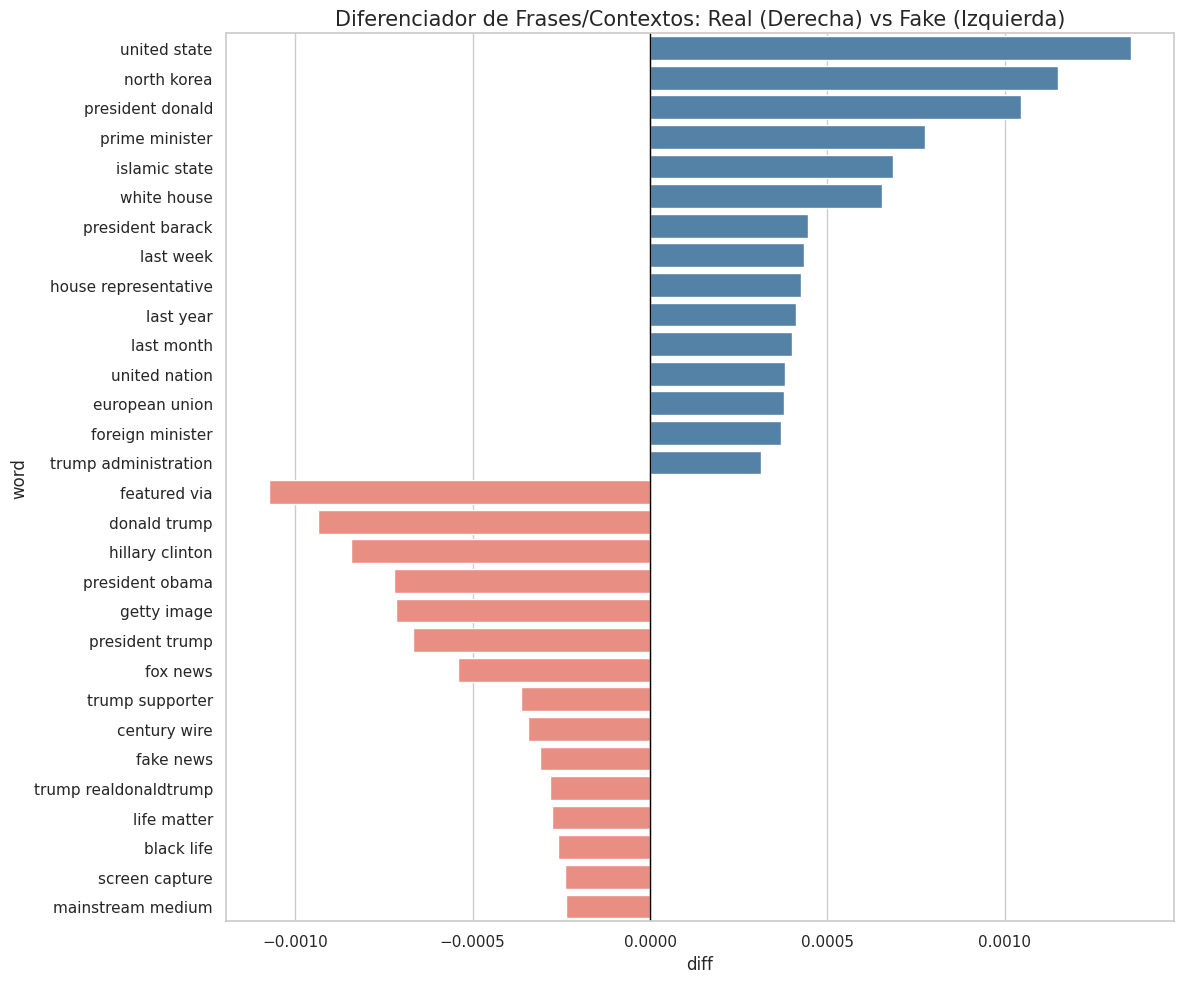

In [ ]:
def graficar_contexto_distintivo(df, n_grama=2, top_n=15):
    vec_t = CountVectorizer(ngram_range=(n_grama, n_grama))
    vec_f = CountVectorizer(ngram_range=(n_grama, n_grama))

    mat_t = vec_t.fit_transform(df[df['target']==1]['text_cleaned_v3'])
    mat_f = vec_f.fit_transform(df[df['target']==0]['text_cleaned_v3'])

    c_t = mat_t.sum(axis=0).A1
    c_f = mat_f.sum(axis=0).A1

    df_t = pd.DataFrame({'word': vec_t.get_feature_names_out(), 'rate_true': c_t / c_t.sum()})
    df_f = pd.DataFrame({'word': vec_f.get_feature_names_out(), 'rate_fake': c_f / c_f.sum()})

    df_diff = pd.merge(df_t, df_f, on='word', how='outer').fillna(0)
    df_diff['diff'] = df_diff['rate_true'] - df_diff['rate_fake']

    comparativa = pd.concat([
        df_diff.sort_values('diff', ascending=False).head(top_n),
        df_diff.sort_values('diff', ascending=True).head(top_n)
    ])

    plt.figure(figsize=(12, 10))
    colors = ['steelblue' if x > 0 else 'salmon' for x in comparativa['diff']]
    sns.barplot(x='diff', y='word', data=comparativa, palette=colors)
    tipo = 'Palabras' if n_grama == 1 else 'Frases/Contextos'
    plt.title(f'Diferenciador de {tipo}: Real (Derecha) vs Fake (Izquierda)', fontsize=15)
    plt.axvline(x=0, color='black', linewidth=1)
    plt.tight_layout()
    plt.show()

graficar_contexto_distintivo(df, n_grama=2)


## Sección 6 · División train / test

El split **80% / 20%** se realiza sobre los **textos limpios** (no sobre la matriz vectorizada)
para evitar *data leakage* al vectorizar. El parámetro `stratify=y` garantiza la misma proporción
de clases en ambos subconjuntos.


In [ ]:
X_text = df['text_cleaned_v3']
y = df['target']

X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    X_text, y, test_size=0.2, random_state=SEED, stratify=y
)

print(f'Train : {X_train_txt.shape[0]:,} noticias')
print(f'Test  : {X_test_txt.shape[0]:,} noticias')

# Diccionario para acumular resultados de todos los modelos
resultados = []


Train : 35,918 noticias
Test  : 8,980 noticias


## Sección 7 · Baseline: TF-IDF

Representamos cada noticia como un vector de **pesos TF-IDF** de bigramas y trigramas.

$$\\text{TF-IDF}(t,d) = \\text{TF}(t,d) \\times \\log\\left(\\frac{N}{\\text{df}(t)}\\right)$$

| Parámetro | Valor | Justificación |
|-----------|-------|---------------|
| `ngram_range` | (2,3) | Captura frases de contexto, no palabras aisladas |
| `max_features` | 5 000 | Limita dimensionalidad y evita sobreajuste |
| `min_df` | 5 | Elimina N-gramas muy raros (ruido) |
| `max_df` | 0.9 | Elimina N-gramas omnipresentes sin poder discriminante |

> El vectorizador se **fitea SOLO con datos de train** para evitar data leakage.


In [ ]:
# Se define función para generar matriz TF-IDF

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(2, 3),
    min_df=5,
    max_df=0.9
)

X_train_tfidf = tfidf.fit_transform(X_train_txt)   # aprende vocabulario SOLO en train
X_test_tfidf  = tfidf.transform(X_test_txt)         # solo transforma test

print(f'Matriz TF-IDF — train: {X_train_tfidf.shape} | test: {X_test_tfidf.shape}')

# Se aplica Regresión Logística como primer modelo de clasificación

clf_tfidf = LogisticRegression(max_iter=1000)
clf_tfidf.fit(X_train_tfidf, y_train)

y_pred_tfidf = clf_tfidf.predict(X_test_tfidf)

print('\n── Reporte TF-IDF + Logistic Regression ──')
print(classification_report(y_test, y_pred_tfidf, target_names=['Fake', 'Real']))

# Guardar métricas
from sklearn.metrics import classification_report as cr
rep_tfidf = cr(y_test, y_pred_tfidf, output_dict=True)
resultados.append({
    'Modelo'    : 'TF-IDF + LR (Baseline)',
    'Accuracy'  : round(rep_tfidf['accuracy'], 4),
    'F1 Macro'  : round(rep_tfidf['macro avg']['f1-score'], 4),
    'Precision' : round(rep_tfidf['macro avg']['precision'], 4),
    'Recall'    : round(rep_tfidf['macro avg']['recall'], 4),
    'Muestra'   : f'{len(y_test):,}'
})

# Top 10 contextos por coeficiente
coef = clf_tfidf.coef_[0]
df_pesos = pd.DataFrame({'contexto': tfidf.get_feature_names_out(), 'peso': coef})
print('\n Top 10 → predicen FAKE (pesos más negativos):')
print(df_pesos.sort_values('peso').head(10)['contexto'].tolist())
print('\n Top 10 → predicen REAL (pesos más positivos):')
print(df_pesos.sort_values('peso', ascending=False).head(10)['contexto'].tolist())


Matriz TF-IDF — train: (35918, 5000) | test: (8980, 5000)

── Reporte TF-IDF + Logistic Regression ──
              precision    recall  f1-score   support

        Fake       0.97      0.96      0.96      4696
        Real       0.96      0.96      0.96      4284

    accuracy                           0.96      8980
   macro avg       0.96      0.96      0.96      8980
weighted avg       0.96      0.96      0.96      8980


 Top 10 → predicen FAKE (pesos más negativos):
['featured via', 'getty image', 'president trump', 'president obama', 'century wire', 'daily mail', 'entire story', 'illegal alien', 'daily caller', 'hillary clinton']

 Top 10 → predicen REAL (pesos más positivos):
['president donald', 'president donald trump', 'house representative', 'nov election', 'news conference', 'chief executive', 'republican senator', 'european union', 'president barack obama', 'last month']


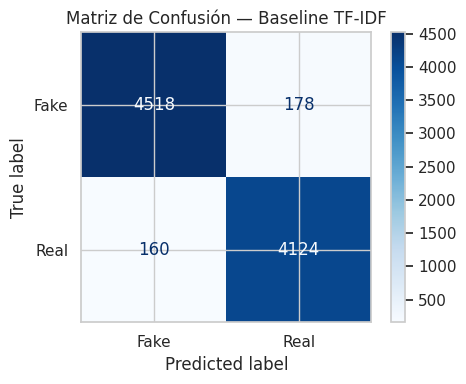

In [ ]:
# Matriz de confusión TF-IDF
cm_tfidf = confusion_matrix(y_test, y_pred_tfidf)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix=cm_tfidf, display_labels=['Fake','Real']).plot(cmap='Blues', ax=ax)
ax.set_title('Matriz de Confusión — Baseline TF-IDF', fontsize=12)
plt.tight_layout()
plt.show()


Epoch 1/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9324 - loss: 0.1755 - val_accuracy: 0.9670 - val_loss: 0.0930
Epoch 2/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9796 - loss: 0.0608 - val_accuracy: 0.9659 - val_loss: 0.0974
Epoch 3/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9882 - loss: 0.0356 - val_accuracy: 0.9676 - val_loss: 0.1015
Epoch 4/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9937 - loss: 0.0209 - val_accuracy: 0.9705 - val_loss: 0.1150


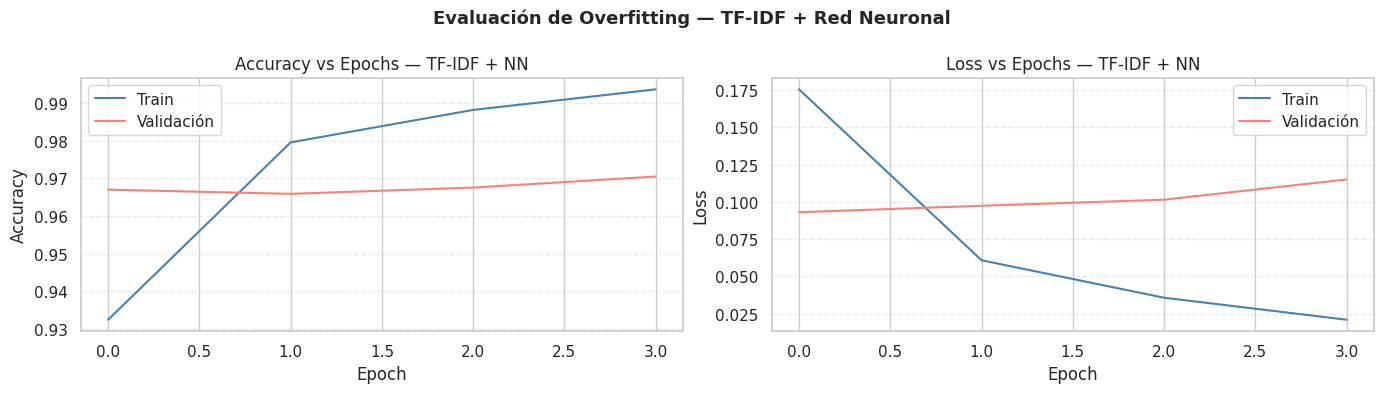


Accuracy en test : 0.9631
Loss en test     : 0.1014


In [ ]:
# Se aplica una Red Neuronal de Clasificación

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Convertir matriz sparse TF-IDF a densa (necesario para Keras)
X_train_tfidf_dense = X_train_tfidf.toarray()
X_test_tfidf_dense  = X_test_tfidf.toarray()

model_tfidf = Sequential([
    Dense(128, activation='relu', input_shape=(X_train_tfidf_dense.shape[1],)),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

model_tfidf.compile(optimizer='adam',
                    loss='binary_crossentropy',
                    metrics=['accuracy'])

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history_tfidf = model_tfidf.fit(
    X_train_tfidf_dense, y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

# Gráficas
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(history_tfidf.history['accuracy'],     label='Train', color='steelblue')
axes[0].plot(history_tfidf.history['val_accuracy'], label='Validación', color='salmon')
axes[0].set_title('Accuracy vs Epochs — TF-IDF + NN')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(axis='y', linestyle='--', alpha=0.4)

axes[1].plot(history_tfidf.history['loss'],     label='Train', color='steelblue')
axes[1].plot(history_tfidf.history['val_loss'], label='Validación', color='salmon')
axes[1].set_title('Loss vs Epochs — TF-IDF + NN')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(axis='y', linestyle='--', alpha=0.4)

plt.suptitle('Evaluación de Overfitting — TF-IDF + Red Neuronal', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Evaluación final en test
loss_test, acc_test = model_tfidf.evaluate(X_test_tfidf_dense, y_test, verbose=0)
print(f'\nAccuracy en test : {acc_test:.4f}')
print(f'Loss en test     : {loss_test:.4f}')


## Sección 8 · Modelo avanzado: ELMo

**ELMo** (Embeddings from Language Models — Peters et al., 2018) genera representaciones **contextuales**:
el vector de cada palabra cambia según la oración completa, usando una arquitectura **BiLSTM** profunda
.

$$\\text{ELMo}_k = \\gamma \\sum_{j=0}^{L} s_j \\mathbf{h}_{k,j}$$

Donde $\\mathbf{h}_{k,j}$ es la representación del token $k$ en la capa $j$ del BiLSTM.

### Optimizaciones de costo computacional
- Usamos la firma `default` de TF Hub que devuelve directamente **un vector por oración** (1 024 dims) — no por token.
- Procesamos en **batches de 32** para no saturar RAM de Colab.



In [ ]:
import tensorflow_hub as hub
import tensorflow as tf

print('Cargando ELMo desde TensorFlow Hub...')
elmo = hub.load('https://tfhub.dev/google/elmo/3')
print('✅ ELMo cargado correctamente. Dimensión de salida: 1024 dims por texto.')


Cargando ELMo desde TensorFlow Hub...
✅ ELMo cargado correctamente. Dimensión de salida: 1024 dims por texto.


In [ ]:
# Parámetro de control de costo computacional

# Usar toda la data disponible para ELMo
train_sample = X_train_txt.reset_index(drop=True)
test_sample  = X_test_txt.reset_index(drop=True)

y_train_elmo = y_train.reset_index(drop=True)
y_test_elmo  = y_test.reset_index(drop=True)

print(f'ELMo — train: {len(train_sample):,} | test: {len(test_sample):,}')


ELMo — train: 35,918 | test: 8,980


In [ ]:
def embed_elmo_batch(texts, model, batch_size=32, max_tokens=100):
    """
    max_tokens: limita cada texto a las primeras N palabras.
    Los artículos periodísticos tienen el contenido más informativo
    en el título y las primeras oraciones (pirámide invertida).
    """
    # Truncar cada texto a max_tokens palabras
    texts = [' '.join(t.split()[:max_tokens]) for t in texts.tolist()]

    all_embs = []
    total_batches = len(texts) // batch_size + 1

    for i in range(0, len(texts), batch_size):
        batch = texts[i:i+batch_size]
        emb = model.signatures['default'](tf.constant(batch))['default']
        all_embs.append(emb.numpy())
        if (i // batch_size) % 10 == 0:
            print(f'  Batch {i//batch_size+1}/{total_batches} procesado...', end='\r')

    print('\n  ✅ Listo.')
    return np.vstack(all_embs)

print('Generando embeddings ELMo — TRAIN...')
X_train_elmo = embed_elmo_batch(train_sample, elmo, batch_size=32, max_tokens=100)

print('Generando embeddings ELMo — TEST...')
X_test_elmo = embed_elmo_batch(test_sample, elmo, batch_size=32, max_tokens=100)

print(f'Shape train ELMo : {X_train_elmo.shape}')
print(f'Shape test  ELMo : {X_test_elmo.shape}')


Generando embeddings ELMo — TRAIN...

  ✅ Listo.
Generando embeddings ELMo — TEST...
  Batch 281/281 procesado...
  ✅ Listo.
Shape train ELMo : (35918, 1024)
Shape test  ELMo : (8980, 1024)



── Reporte ELMo + Logistic Regression ──
              precision    recall  f1-score   support

        Fake       0.96      0.96      0.96      4696
        Real       0.96      0.96      0.96      4284

    accuracy                           0.96      8980
   macro avg       0.96      0.96      0.96      8980
weighted avg       0.96      0.96      0.96      8980



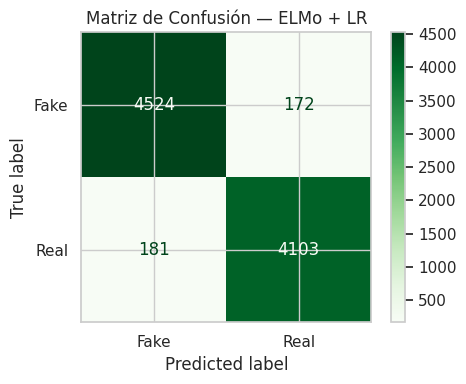

In [ ]:
# Se aplica Regresión Logística para clasificación

clf_elmo = LogisticRegression(max_iter=1000)
clf_elmo.fit(X_train_elmo, y_train_elmo)

y_pred_elmo = clf_elmo.predict(X_test_elmo)

print('\n── Reporte ELMo + Logistic Regression ──')
print(classification_report(y_test_elmo, y_pred_elmo, target_names=['Fake', 'Real']))

rep_elmo = cr(y_test_elmo, y_pred_elmo, output_dict=True)
resultados.append({
    'Modelo'    : 'ELMo + LR',
    'Accuracy'  : round(rep_elmo['accuracy'], 4),
    'F1 Macro'  : round(rep_elmo['macro avg']['f1-score'], 4),
    'Precision' : round(rep_elmo['macro avg']['precision'], 4),
    'Recall'    : round(rep_elmo['macro avg']['recall'], 4),
    'Muestra'   : f'{len(y_test_elmo):,}'
})

# Matriz de confusión ELMo
cm_elmo = confusion_matrix(y_test_elmo, y_pred_elmo)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix=cm_elmo, display_labels=['Fake','Real']).plot(cmap='Greens', ax=ax)
ax.set_title('Matriz de Confusión — ELMo + LR', fontsize=12)
plt.tight_layout()
plt.show()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9099 - loss: 0.2283 - val_accuracy: 0.9332 - val_loss: 0.1710
Epoch 2/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9334 - loss: 0.1690 - val_accuracy: 0.9253 - val_loss: 0.1801
Epoch 3/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9403 - loss: 0.1537 - val_accuracy: 0.9442 - val_loss: 0.1412
Epoch 4/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9457 - loss: 0.1411 - val_accuracy: 0.9482 - val_loss: 0.1330
Epoch 5/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9490 - loss: 0.1319 - val_accuracy: 0.9403 - val_loss: 0.1453
Epoch 6/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9515 - loss: 0.1262 - val_accuracy: 0.9514 - val_loss: 0.1255
Epoch 7/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9545 - loss: 0.1192 - val_accuracy: 0.9485 - val_loss: 0.1279
Epoch 8/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9576 - loss: 0.1128 - val_accuracy: 0.

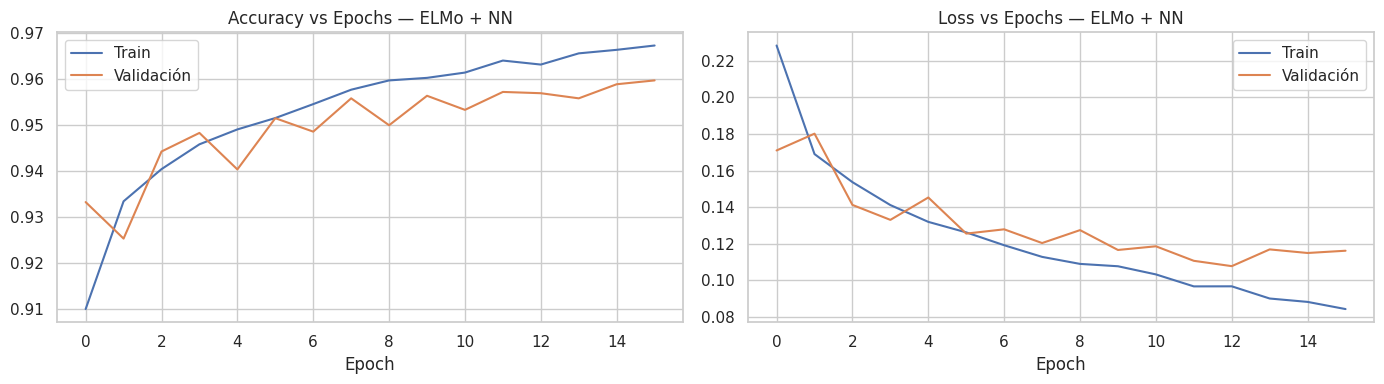

In [ ]:
# Se aplica Red Neuronal para clasificación

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

model = Sequential([
    Dense(128, activation='relu', input_shape=(1024,)),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train_elmo, y_train_elmo,
    validation_split=0.2,
    epochs=20,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

# Gráficas de overfitting clásicas
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(history.history['accuracy'],     label='Train')
axes[0].plot(history.history['val_accuracy'], label='Validación')
axes[0].set_title('Accuracy vs Epochs — ELMo + NN')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(history.history['loss'],     label='Train')
axes[1].plot(history.history['val_loss'], label='Validación')
axes[1].set_title('Loss vs Epochs — ELMo + NN')
axes[1].set_xlabel('Epoch')
axes[1].legend()

plt.tight_layout()
plt.show()
